1. **Introduction**


This dataset contains physical measurements and habitat details for 344 penguins collected from three islands in the Palmer Archipelago, Antarctica.

Our Questions to Explore:

1. What are the key physical differences between the 3 penguin species (Adelie, Chinstrap, Gentoo)?

2. Does body mass differ significantly between male and female penguins?

3. Which physical feature (bill length, bill depth, flipper length, or body mass) is most strongly correlated with body mass?

4. Do penguins on Biscoe island weigh more on average than penguins on Dream island?

2. **Load**

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

try:
    df = pd.read_csv("penguins.csv")
except FileNotFoundError:
    sns.load_dataset("penguins").to_csv("penguins.csv", index=False)
    df = pd.read_csv("penguins.csv")

3. **Inspect**


In [19]:
df = df.rename(columns={"sex": "gender"})

print("Shape:", df.shape)
df.info()
print(df.describe().round(1))
print("Missing values:\n", df.isna().sum())
print(df["species"].value_counts())

Shape: (344, 7)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   gender             333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           342.0          342.0              342.0        342.0
mean             43.9           17.2              200.9       4201.8
std               5.5            2.0               14.1        802.0
min              32.1           13.1              172.0       2700.0
25%              39.2           15.6              190.0       355

4. **Clean**



In [20]:
df = df.dropna(subset=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "gender"])

# Create derived features
df["body_mass_kg"] = df["body_mass_g"] / 1000
df["size_group"] = np.where(df["body_mass_g"] < 4000, "Small", "Large")
df["is_male"] = np.where(df["gender"] == "Male", 1, 0)

print("Shape after cleaning:", df.shape)
print("Remaining missing values:\n", df.isna().sum())

Shape after cleaning: (333, 10)
Remaining missing values:
 species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
gender               0
body_mass_kg         0
size_group           0
is_male              0
dtype: int64


5. **Explore (Distributions, Outliers, and Relations)**

 Distribution (Histogram & Count Plot)

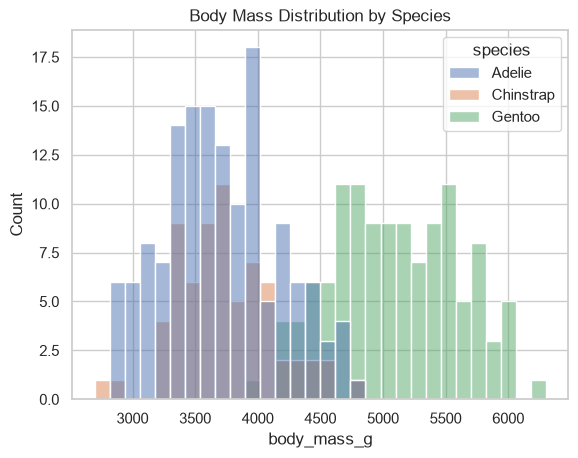

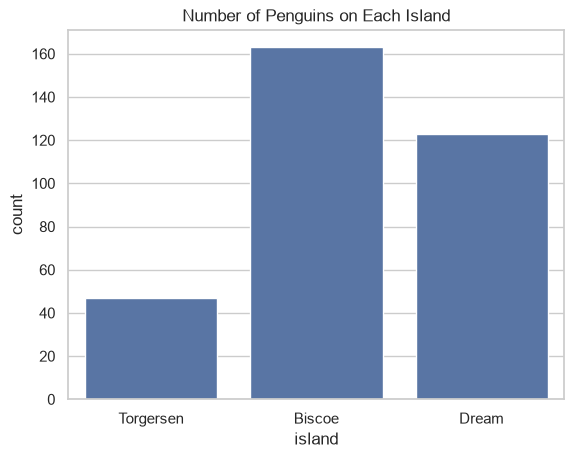

In [21]:
sns.histplot(data=df, x="body_mass_g", bins=30, hue="species")
plt.title("Body Mass Distribution by Species")
plt.show()

sns.countplot(data=df, x="island")
plt.title("Number of Penguins on Each Island")
plt.show()


Outliers (IQR Rule on Body Mass)

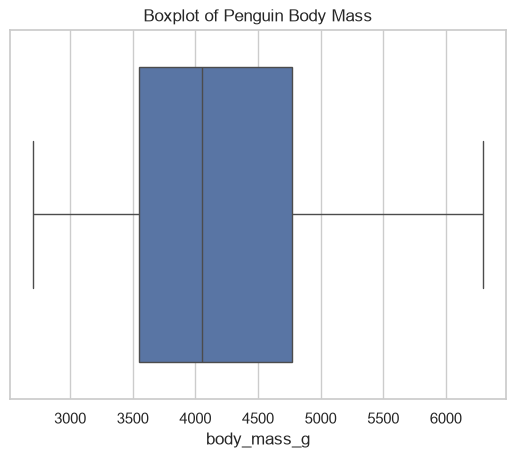

Q1: 3550.0  Q3: 4775.0  IQR: 1225.0
Upper fence: 6612.5
Number of outliers: 0


In [22]:
sns.boxplot(data=df, x="body_mass_g")
plt.title("Boxplot of Penguin Body Mass")
plt.show()

q1 = df["body_mass_g"].quantile(0.25)
q3 = df["body_mass_g"].quantile(0.75)
iqr = q3 - q1
high = q3 + 1.5 * iqr

print("Q1:", q1, " Q3:", q3, " IQR:", round(iqr, 1))
print("Upper fence:", round(high, 1))
outliers = df[df["body_mass_g"] > high]
print("Number of outliers:", len(outliers))

Relations (Correlation Heatmap)

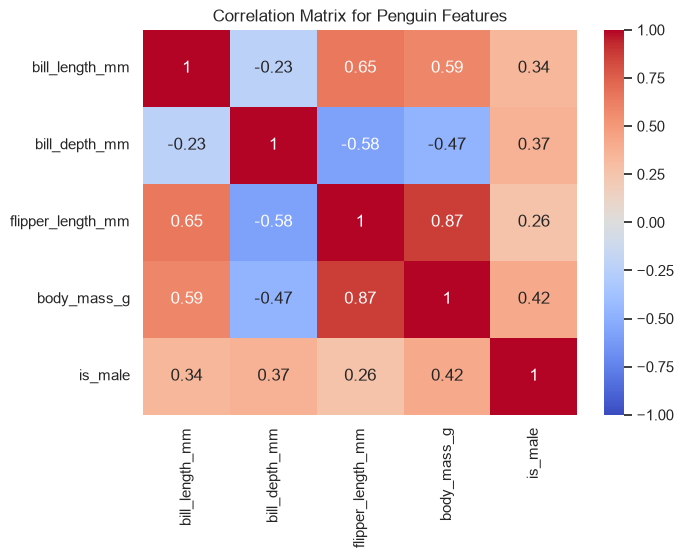

Feature most strongly correlated with body mass: flipper_length_mm (Correlation: 0.87)


In [23]:
cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "is_male"]

plt.figure(figsize=(7, 5))
corr_matrix = df[cols].corr().round(2)
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix for Penguin Features")
plt.show()

# Identify feature most strongly correlated with body mass
body_mass_corr = corr_matrix["body_mass_g"].drop("body_mass_g")
strongest_feature = body_mass_corr.idxmax()
print(f"Feature most strongly correlated with body mass: {strongest_feature} (Correlation: {body_mass_corr[strongest_feature]})")

6. **Findings**



In [24]:
print(df.groupby("species")["body_mass_g"].mean().round(1))

species
Adelie       3706.2
Chinstrap    3733.1
Gentoo       5092.4
Name: body_mass_g, dtype: float64


In [25]:
print("--- FINDINGS & ANSWERS TO RESEARCH QUESTIONS ---")

print("\n1. Key Physical Differences Across Species (Means):")
species_means = df.groupby("species")[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]].mean().round(1)
print(species_means)

print("\n2. Body Mass Comparison by Gender:")
gender_means = df.groupby("gender")["body_mass_g"].mean().round(1)
print(gender_means)

species_gender_means = df.groupby(["species", "gender"])["body_mass_g"].mean().round(1)
print("\nBody Mass by Species and Gender:\n", species_gender_means)

print("\n4. Average Body Mass by Island:")
island_means = df.groupby("island")["body_mass_g"].mean().round(1)
print(island_means)


--- FINDINGS & ANSWERS TO RESEARCH QUESTIONS ---

1. Key Physical Differences Across Species (Means):
           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
species                                                                 
Adelie               38.8           18.3              190.1       3706.2
Chinstrap            48.8           18.4              195.8       3733.1
Gentoo               47.6           15.0              217.2       5092.4

2. Body Mass Comparison by Gender:
gender
Female    3862.3
Male      4545.7
Name: body_mass_g, dtype: float64

Body Mass by Species and Gender:
 species    gender
Adelie     Female    3368.8
           Male      4043.5
Chinstrap  Female    3527.2
           Male      3939.0
Gentoo     Female    4679.7
           Male      5484.8
Name: body_mass_g, dtype: float64

4. Average Body Mass by Island:
island
Biscoe       4719.2
Dream        3718.9
Torgersen    3708.5
Name: body_mass_g, dtype: float64


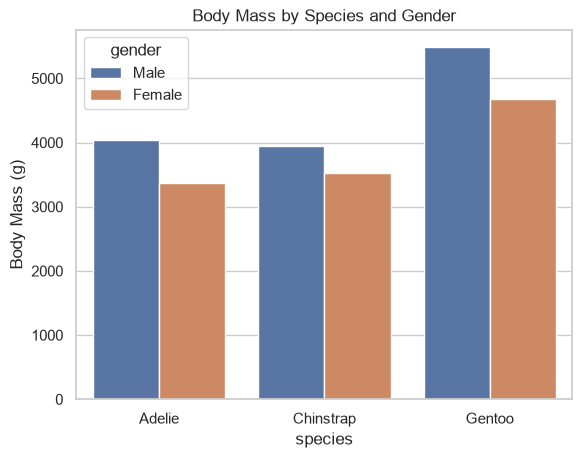

In [26]:
sns.barplot(data=df, x="species", y="body_mass_g", hue="gender", errorbar=None)
plt.title("Body Mass by Species and Gender")
plt.ylabel("Body Mass (g)")
plt.savefig("mass_by_species_and_sex.png", dpi=150, bbox_inches="tight")
plt.show()

7. **Conclusion**

 Summary Answers based on actual results:
 1. Gentoo penguins are generally the largest species across all physical measurements (highest body mass and flipper length), whereas Adelie penguins have shorter flippers and smaller body mass.
 2. On average, male penguins consistently have a higher body mass than female penguins across all species categories.
 3. Flipper length shows the strongest positive correlation with overall body mass among the physical features analyzed.
 4. Penguins located on Biscoe island exhibit a higher average body mass compared to those on Dream island, largely driven by the dominance of the larger Gentoo population on Biscoe island.